In [1]:
import at3d
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import netCDF4 as nc
from collections import OrderedDict
import os

In [2]:
def save_measurements(file_name, sensors):
    """
    Method to save only a Sensor Dict object. Useful for preparing real 
    satellite observations to be used in a retreival. Adapted from 
    at3d.util.save_forward_model.

    Parameters
    ----------
    file_name : string
        The path to the file that will be created and saved to. If it exists, an
        integer is appended to the file name until it can be created safely.
    sensors : at3d.containers.SensorsDict
    """
    if not isinstance(sensors, at3d.containers.SensorsDict):
        raise TypeError(
            "`sensors` should be an instance of '{}'".format(at3d.containers.SensorsDict)
        )
    
    # make a safe file name. We always want one that works
    # as we might have spent a lot of time to make the input data.
    counter = 1
    initial_file_name = file_name
    while os.path.exists(file_name):
        if counter > 1:
            file_name = '{}_{}.nc'.format(file_name[:-5], counter)
        else:
            file_name = '{}_{}.nc'.format(file_name[:-3], counter)
        counter += 1

    if counter > 1:
        warnings.warn("file_name '{}' already exists, your file is now at '{}'".format(
            initial_file_name,file_name), category=RuntimeWarning)

    save_file = nc.Dataset(file_name, 'w')
    save_file.close()
    for i, (key, sensor) in enumerate(sensors.items()):
        for j, image in enumerate(sensor['sensor_list']):
            image.to_netcdf(file_name, 'a', group='sensors/{}/{:d}'.format(key, j))

def load_measurements(file_name):
    """
    Load from netCDF the sensors that were saved using 'save_forward_model'
    above. Adapted from at3d.util.load_forward_model.
    """
    dataset = nc.Dataset(file_name)

    groups = dataset.groups
    sensors = groups['sensors'].groups
    sensor_dict = at3d.containers.SensorsDict()

    for key, sensor in sensors.items():
        sensor_list = []
        for i, image in sensor.groups.items():
            sensor_dataset = xr.open_dataset(xr.backends.NetCDF4DataStore(dataset[
                'sensors/{}/{}'.format(key, i)]))
            sensor_dataset['stokes'] = (['stokes_index'],sensor_dataset['stokes'].data.astype(bool))
            sensor_dataset['use_subpixel_rays'] = sensor_dataset['use_subpixel_rays'].data.astype(bool)
            sensor_dict.add_sensor(key, sensor_dataset)
    return sensor_dict


In [3]:
expr_dir = '../dev/'
rte_grid = xr.load_dataset('{}rte_grid.nc'.format(expr_dir))
measurements = load_measurements('{}measurements.nc'.format(expr_dir))
LUT = xr.load_dataset('./LUT_1D.nc')

In [4]:
LUT

<xarray.Dataset>
Dimensions:  (brf: 441)
Coordinates:
  * brf      (brf) float64 0.02795 0.0365 0.03662 0.03676 ... 1.079 1.081 1.083
Data variables:
    tau      (brf) float64 0.0 0.1084 0.11 0.1117 ... 81.01 82.25 83.51 84.79

In [4]:
cam = measurements['MISR']['sensor_list'][4]
measured_brf = (cam.I.copy(deep=True)*np.pi/cam.mu0).data
measured_tau = np.zeros(measured_brf.shape)
for i, m_brf in enumerate(measured_brf):
    measured_tau[i] = LUT.sel(brf=m_brf, method='nearest').tau.data
measured_tau[measured_tau <= np.min(LUT.tau.data)] = 0
cam['tau'] = (['nrays'], measured_tau)

In [5]:
np.min(LUT.brf.data)

0.027953467500415396

In [6]:
np.min(LUT.tau.data)

0.0

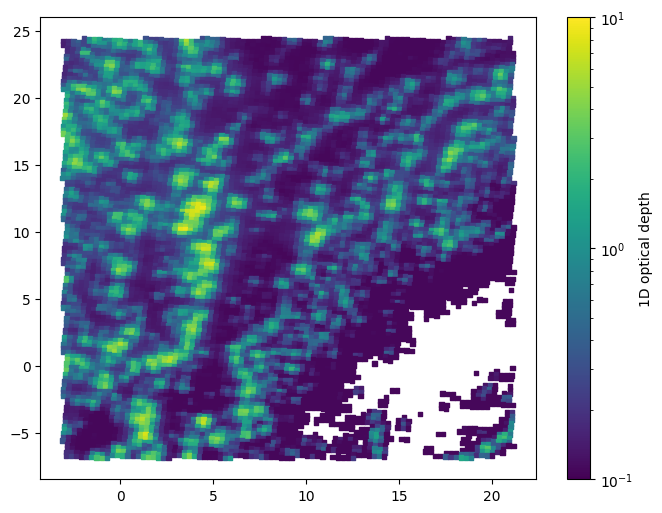

In [7]:
f, ax = plt.subplots(1, 1, figsize=(8,6))
c = ax.scatter(cam.ray_x, cam.ray_y, c=cam.tau, marker='s', s=10, norm=colors.LogNorm(vmin=0.1, vmax=10))
# c = ax.scatter(cam.ray_x, cam.ray_y, c=cam.tau, marker='s', s=10, vmin=0.0, vmax=10)
plt.colorbar(c, label='1D optical depth')

In [33]:
save_measurements('../dev/measurements_1Dtau.nc', measurements)